In [1]:
options(timeout = 1200)  # 20 minutes

In [2]:
options(repr.plot.width = 14, repr.plot.height = 7)

In [3]:
library(Seurat)
library(SeuratData)
library(patchwork)

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.5 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


── Installed datasets ──────────────────────────────── SeuratData v0.2.2.9002 ──

✔ ifnb 3.1.0                            


────────────────────────────────────── Key ─────────────────────────────────────

✔ Dataset loaded successfully
❯ Dataset built with a newer version of Seurat than installed
❓ Unknown version of Seurat installed




In [4]:
# install dataset
InstallData("ifnb")

Warning message:
“The following packages are already installed and will not be reinstalled: ifnb”


In [5]:
# load dataset
ifnb <- LoadData("ifnb")

Validating object structure

Updating object slots

Ensuring keys are in the proper structure

Warning message:
“Assay RNA changing from Assay to Assay”
Ensuring keys are in the proper structure

Ensuring feature names don't have underscores or pipes

Updating slots in RNA

Validating object structure for Assay ‘RNA’

Object representation is consistent with the most current Seurat version

Warning message:
“Assay RNA changing from Assay to Assay5”


In [6]:
ifnb

An object of class Seurat 
14053 features across 13999 samples within 1 assay 
Active assay: RNA (14053 features, 0 variable features)
 2 layers present: counts, data

In [7]:
ifnb[[]]

,orig.ident,nCount_RNA,nFeature_RNA,stim,seurat_annotations
,<chr>,<dbl>,<int>,<chr>,<fct>
AAACATACATTTCC.1,IMMUNE_CTRL,3017,877,CTRL,CD14 Mono
AAACATACCAGAAA.1,IMMUNE_CTRL,2481,713,CTRL,CD14 Mono
AAACATACCTCGCT.1,IMMUNE_CTRL,3420,850,CTRL,CD14 Mono
AAACATACCTGGTA.1,IMMUNE_CTRL,3156,1109,CTRL,pDC
AAACATACGATGAA.1,IMMUNE_CTRL,1868,634,CTRL,CD4 Memory T
AAACATACGGCATT.1,IMMUNE_CTRL,1581,557,CTRL,CD14 Mono
AAACATACTGCGTA.1,IMMUNE_CTRL,2747,980,CTRL,T activated
AAACATACTGCTGA.1,IMMUNE_CTRL,1341,581,CTRL,CD4 Naive T
AAACATTGAGTGTC.1,IMMUNE_CTRL,2155,880,CTRL,CD8 T


In [8]:
ifnb[["RNA"]]

Assay (v5) data with 14053 features for 13999 cells
First 10 features:
 AL627309.1, RP11-206L10.2, LINC00115, NOC2L, KLHL17, PLEKHN1, HES4,
ISG15, AGRN, C1orf159 
Layers:
 counts, data 

In [9]:
ifnb[["RNA"]]$counts 

  [[ suppressing 32 column names ‘AAACATACATTTCC.1’, ‘AAACATACCAGAAA.1’, ‘AAACATACCTCGCT.1’ ... ]]

  [[ suppressing 32 column names ‘AAACATACATTTCC.1’, ‘AAACATACCAGAAA.1’, ‘AAACATACCTCGCT.1’ ... ]]

  [[ suppressing 32 column names ‘AAACATACATTTCC.1’, ‘AAACATACCAGAAA.1’, ‘AAACATACCTCGCT.1’ ... ]]



14053 x 13999 sparse Matrix of class "dgCMatrix"
                                                                                            
AL627309.1      .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  .  .  . .  .  . .  . . .  .
RP11-206L10.2   .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  .  .  . .  .  . .  . . .  .
LINC00115       .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  .  .  . .  .  . .  . . .  .
NOC2L           .  .  .  .  .  .  . .  .  .  . 1 . .  .  . .  .  .  .  . .  .  . .  . . .  .
KLHL17          .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  .  .  . .  .  . .  . . .  .
PLEKHN1         .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  1  .  . .  .  . .  . . .  .
HES4            .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  .  .  . .  1  . .  . . .  .
ISG15           .  .  1  1  .  3  1 .  .  .  . . . .  1  1 1  1  3  .  . .  .  . .  . . 1  .
AGRN            .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  .  .  . .  .  . .  . . .  .
C1orf159        .  . 

In [10]:
# split the RNA measurements into two layers one for control cells, one for stimulated cells

ifnb[["RNA"]] <- split(ifnb[["RNA"]], f = ifnb$stim)
ifnb

An object of class Seurat 
14053 features across 13999 samples within 1 assay 
Active assay: RNA (14053 features, 0 variable features)
 4 layers present: counts.CTRL, counts.STIM, data.CTRL, data.STIM

In [11]:
ifnb[["RNA"]]

Assay (v5) data with 14053 features for 13999 cells
First 10 features:
 AL627309.1, RP11-206L10.2, LINC00115, NOC2L, KLHL17, PLEKHN1, HES4,
ISG15, AGRN, C1orf159 
Layers:
 counts.CTRL, counts.STIM, data.CTRL, data.STIM 

In [12]:
ifnb[["RNA"]]$counts.CTRL

  [[ suppressing 32 column names ‘AAACATACATTTCC.1’, ‘AAACATACCAGAAA.1’, ‘AAACATACCTCGCT.1’ ... ]]

  [[ suppressing 32 column names ‘AAACATACATTTCC.1’, ‘AAACATACCAGAAA.1’, ‘AAACATACCTCGCT.1’ ... ]]

  [[ suppressing 32 column names ‘AAACATACATTTCC.1’, ‘AAACATACCAGAAA.1’, ‘AAACATACCTCGCT.1’ ... ]]



14053 x 6548 sparse Matrix of class "dgCMatrix"
                                                                                            
AL627309.1      .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  .  .  . .  .  . .  . . .  .
RP11-206L10.2   .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  .  .  . .  .  . .  . . .  .
LINC00115       .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  .  .  . .  .  . .  . . .  .
NOC2L           .  .  .  .  .  .  . .  .  .  . 1 . .  .  . .  .  .  .  . .  .  . .  . . .  .
KLHL17          .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  .  .  . .  .  . .  . . .  .
PLEKHN1         .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  1  .  . .  .  . .  . . .  .
HES4            .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  .  .  . .  1  . .  . . .  .
ISG15           .  .  1  1  .  3  1 .  .  .  . . . .  1  1 1  1  3  .  . .  .  . .  . . 1  .
AGRN            .  .  .  .  .  .  . .  .  .  . . . .  .  . .  .  .  .  . .  .  . .  . . .  .
C1orf159        .  .  

In [13]:
ifnb[["RNA"]]$counts.STIM

  [[ suppressing 32 column names ‘AAACATACCAAGCT.1’, ‘AAACATACCCCTAC.1’, ‘AAACATACCCGTAA.1’ ... ]]

  [[ suppressing 32 column names ‘AAACATACCAAGCT.1’, ‘AAACATACCCCTAC.1’, ‘AAACATACCCGTAA.1’ ... ]]

  [[ suppressing 32 column names ‘AAACATACCAAGCT.1’, ‘AAACATACCCCTAC.1’, ‘AAACATACCCGTAA.1’ ... ]]



14053 x 7451 sparse Matrix of class "dgCMatrix"
                                                                                         
AL627309.1      .  . . . .  .  .  .   .  .  .  .   .  . .  .  .  .   .  .  .   .   .  . .
RP11-206L10.2   .  . . . .  .  .  .   .  .  .  .   .  . .  .  .  .   .  .  .   .   .  . .
LINC00115       .  . . . .  .  .  .   .  .  .  .   .  . .  .  .  .   .  .  .   .   .  . .
NOC2L           .  . . . .  1  .  .   .  .  .  .   .  . .  .  .  .   .  1  .   .   .  . .
KLHL17          .  . . . .  .  .  .   .  .  .  .   .  . .  .  .  .   .  .  .   .   .  . .
PLEKHN1         .  . . . .  .  .  .   .  .  .  .   .  . .  .  .  .   .  .  .   .   .  . .
HES4            .  . . . .  .  .  .   1  .  .  .   2  . 4  .  .  .   3  .  .   1   .  . .
ISG15          15 25 7 7 7 58  5 62 115 11 13 20 178 95 3 22 28 94 146  . 84 173 126 91 9
AGRN            .  . . . .  .  .  .   .  .  .  .   .  . .  .  .  .   .  .  .   .   .  . .
C1orf159        .  . . . .  .  .  .   .  .  .  .   .

In [14]:
# run standard analysis workflow
ifnb <- NormalizeData(ifnb)

Normalizing layer: counts.CTRL

Normalizing layer: counts.STIM



In [15]:
ifnb <- FindVariableFeatures(ifnb)

Finding variable features for layer counts.CTRL

Finding variable features for layer counts.STIM



In [16]:
ifnb <- ScaleData(ifnb)

Centering and scaling data matrix



In [17]:
ifnb <- RunPCA(ifnb)

PC_ 1 
Positive:  TYROBP, C15orf48, FCER1G, CST3, SOD2, ANXA5, FTL, TYMP, TIMP1, CD63 
	   LGALS1, CTSB, S100A4, LGALS3, KYNU, PSAP, FCN1, NPC2, ANXA2, S100A11 
	   IGSF6, LYZ, SPI1, APOBEC3A, CD68, CTSL, SDCBP, NINJ1, HLA-DRA, CCL2 
Negative:  NPM1, CCR7, GIMAP7, LTB, CD7, SELL, CD2, TMSB4X, TRAT1, IL7R 
	   IL32, RHOH, ITM2A, RGCC, LEF1, CD3G, ALOX5AP, CREM, NHP2, PASK 
	   MYC, SNHG8, TSC22D3, GPR171, BIRC3, NOP58, RARRES3, CD27, SRM, CD8B 
PC_ 2 
Positive:  ISG15, ISG20, IFIT3, IFIT1, LY6E, TNFSF10, IFIT2, MX1, IFI6, RSAD2 
	   CXCL10, OAS1, CXCL11, IFITM3, MT2A, OASL, TNFSF13B, IDO1, IL1RN, APOBEC3A 
	   GBP1, CCL8, HERC5, FAM26F, GBP4, HES4, WARS, VAMP5, DEFB1, XAF1 
Negative:  IL8, CLEC5A, CD14, VCAN, S100A8, IER3, MARCKSL1, IL1B, PID1, CD9 
	   GPX1, PHLDA1, INSIG1, PLAUR, PPIF, THBS1, OSM, SLC7A11, GAPDH, CTB-61M7.2 
	   LIMS1, S100A9, GAPT, CXCL3, ACTB, C19orf59, CEBPB, OLR1, MGST1, FTH1 
PC_ 3 
Positive:  HLA-DQA1, CD83, HLA-DQB1, CD74, HLA-DPA1, HLA-DRA, HLA-DRB1, HLA-DPB1,

In [18]:
ifnb <- FindNeighbors(ifnb, dims = 1:30, reduction = "pca")

Computing nearest neighbor graph

Computing SNN



In [19]:
ifnb <- FindClusters(ifnb, resolution = 2)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 13999
Number of edges: 555146

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8153
Number of communities: 26
Elapsed time: 1 seconds


In [20]:
ifnb <- RunUMAP(ifnb, dims = 1:30, reduction = "pca", reduction.name = "umap.unintegrated")

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
17:02:33 UMAP embedding parameters a = 0.9922 b = 1.112

17:02:33 Read 13999 rows and found 30 numeric columns

17:02:33 Using Annoy for neighbor search, n_neighbors = 30

17:02:33 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

17:02:34 Writing NN index file to temp file /var/folders/s0/b80lx8jj2d70y40_0dnz9c680000gn/T//RtmpGZNQeT/file672f3cf4b892

17:02:34 Searching Annoy index using 1 thread, search_k = 3000

17:02:36 Annoy recall = 100%

17:02:36 Commencing smooth kNN distance calibra

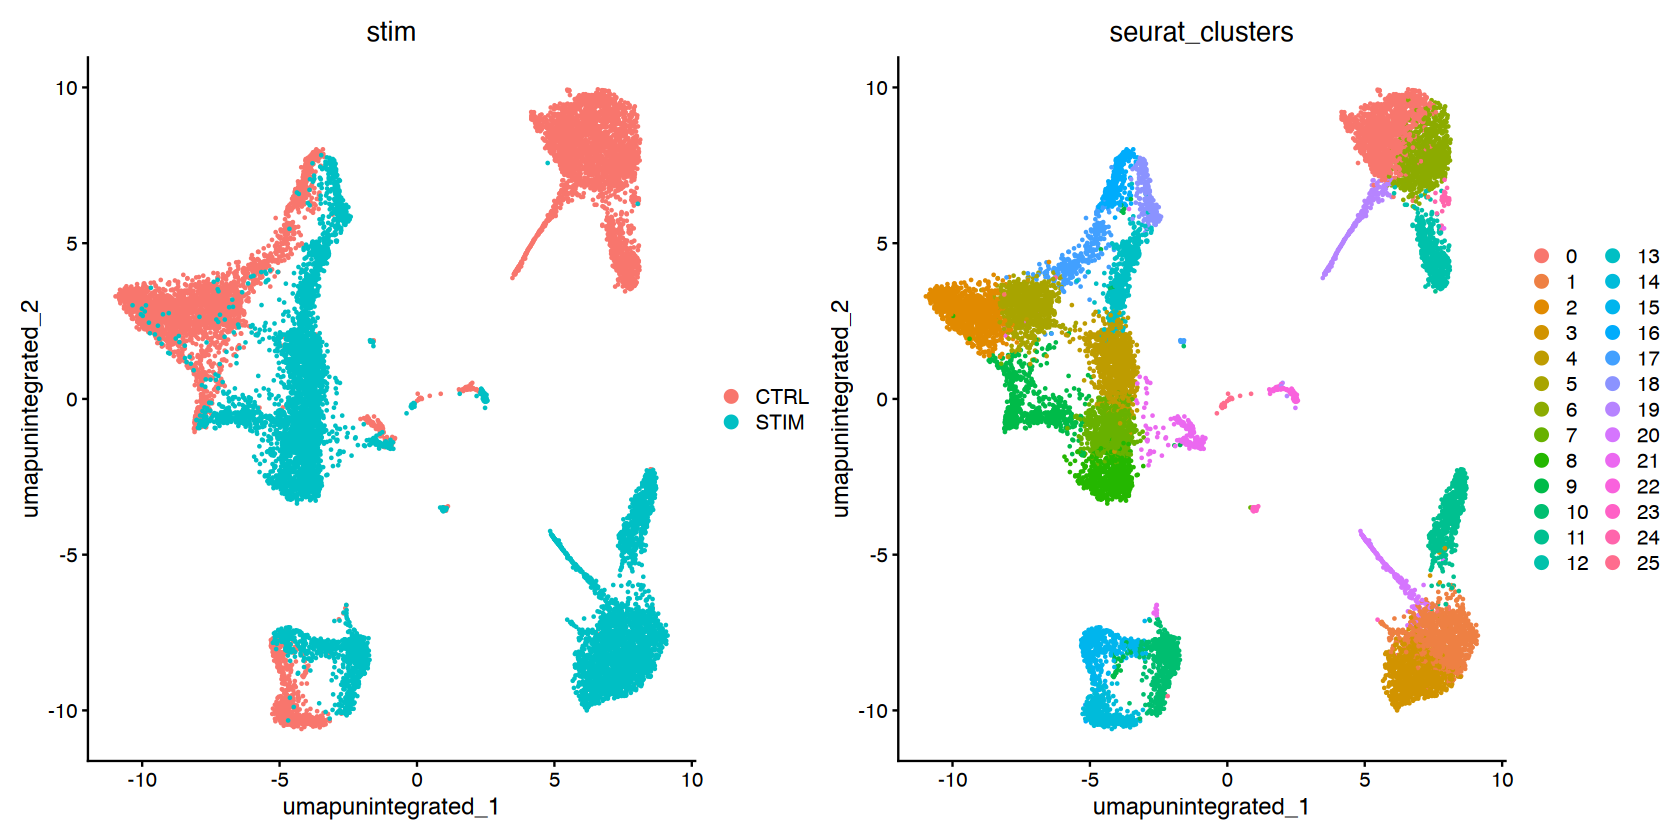

In [21]:
DimPlot(ifnb, reduction = "umap.unintegrated", group.by = c("stim", "seurat_clusters"))

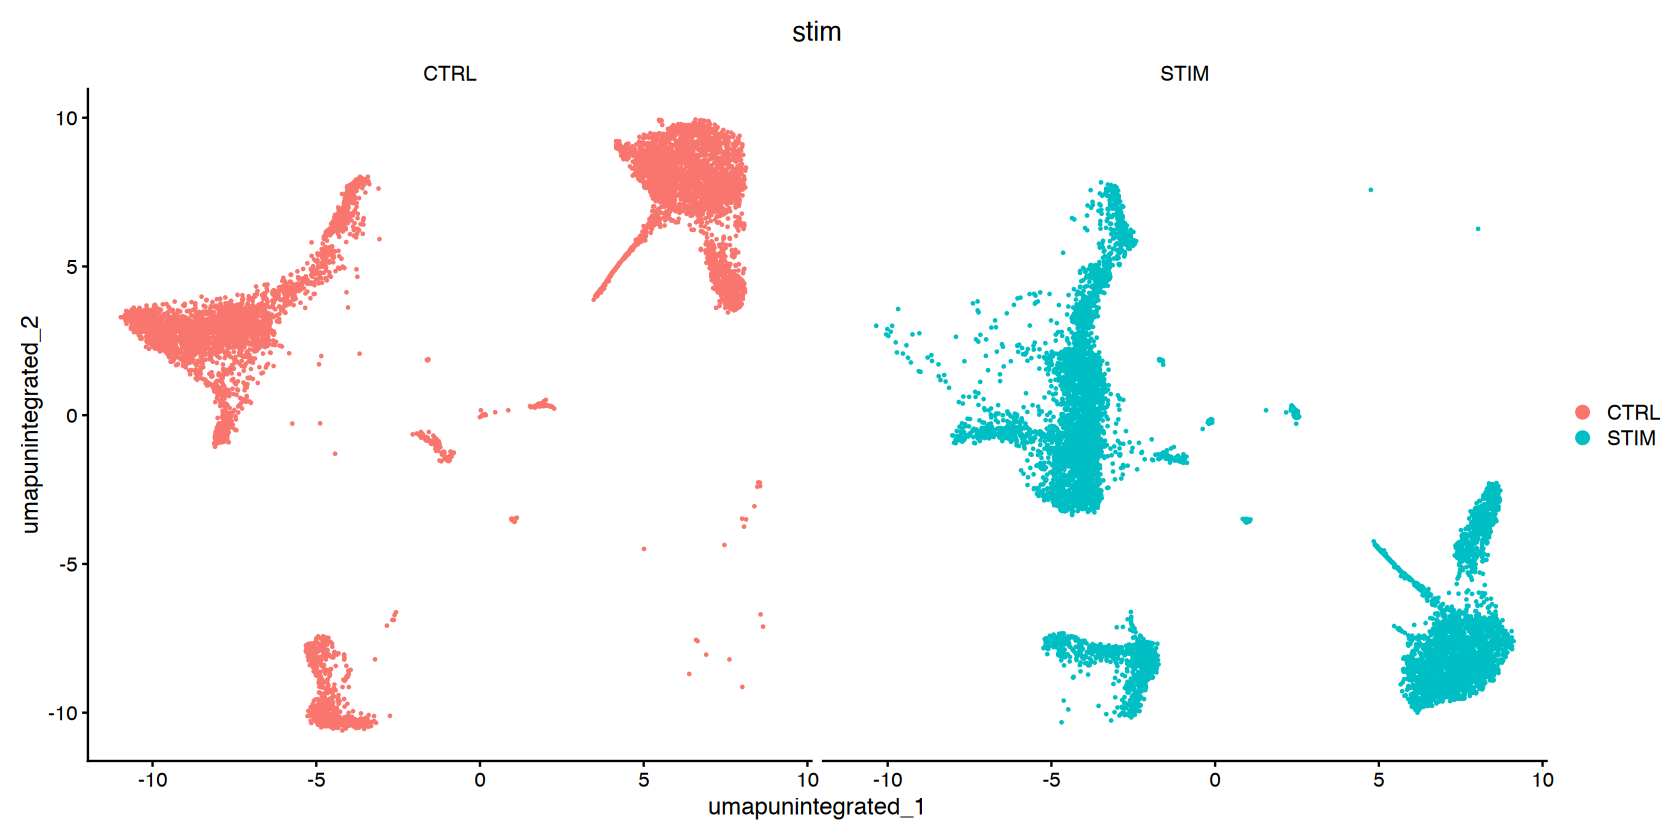

In [22]:
DimPlot(ifnb, reduction = "umap.unintegrated", group.by = "stim", split.by = "stim", ncol=2)

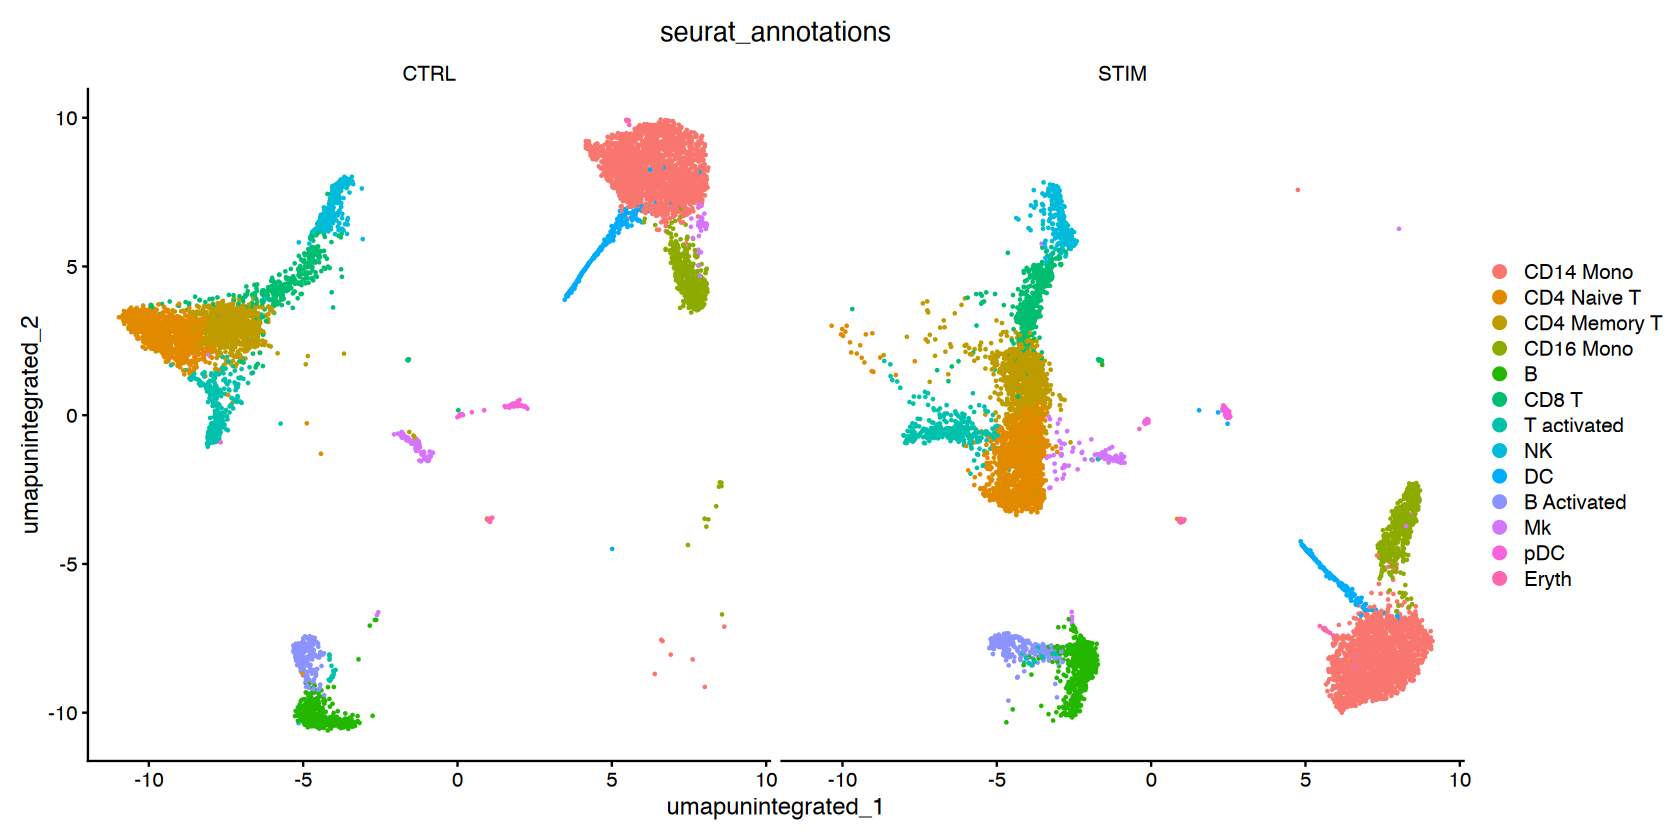

In [23]:
DimPlot(ifnb, reduction = "umap.unintegrated", group.by = "seurat_annotations", split.by = "stim", ncol=2)

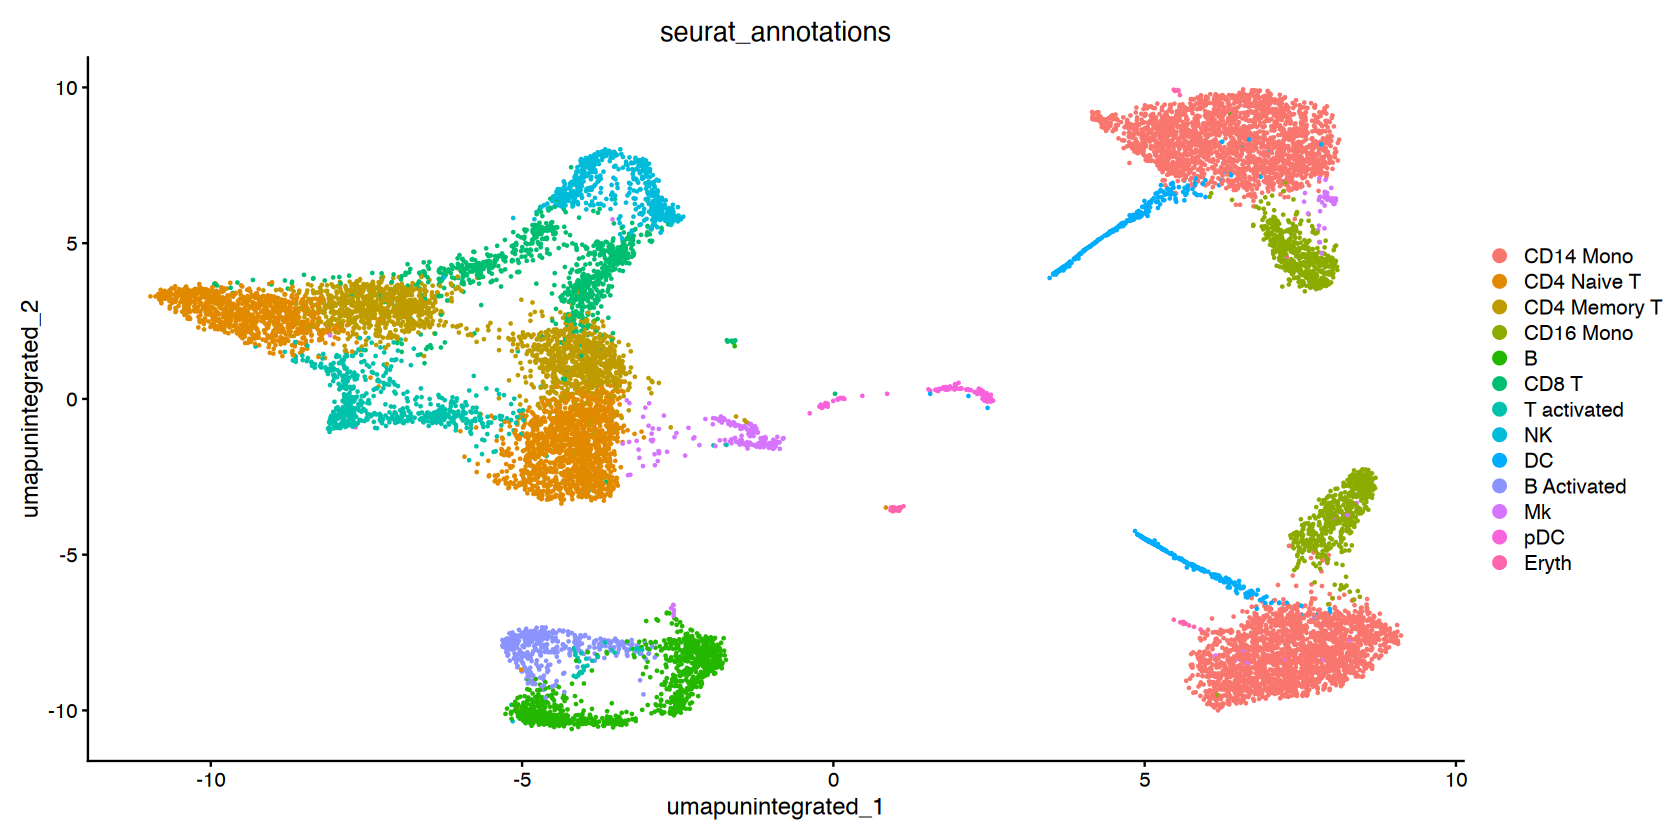

In [24]:
DimPlot(ifnb, reduction = "umap.unintegrated", group.by = "seurat_annotations")

In [25]:
ifnb <- IntegrateLayers(object = ifnb, method = CCAIntegration, orig.reduction = "pca", new.reduction = "integrated.cca",
    verbose = TRUE)

Finding all pairwise anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 13620 anchors

Merging dataset 1 into 2

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data



In [26]:
dim(ifnb[["RNA"]]$scale.data)

[1]  2000 13999

In [27]:
# re-join layers after integration
ifnb[["RNA"]] <- JoinLayers(ifnb[["RNA"]])

In [28]:
ifnb[["RNA"]]

Assay (v5) data with 14053 features for 13999 cells
Top 10 variable features:
 HBB, HBA2, HBA1, CCL4, CCL3, CCL7, TXN, GNLY, PPBP, APOBEC3B 
Layers:
 data, counts, scale.data 

In [29]:
ifnb <- FindNeighbors(ifnb, reduction = "integrated.cca", dims = 1:30)

Computing nearest neighbor graph

Computing SNN



In [30]:
ifnb <- FindClusters(ifnb, resolution = 1)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 13999
Number of edges: 590765

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8445
Number of communities: 19
Elapsed time: 1 seconds


In [31]:
ifnb <- RunUMAP(ifnb, dims = 1:30, reduction = "integrated.cca")

17:03:00 UMAP embedding parameters a = 0.9922 b = 1.112

17:03:00 Read 13999 rows and found 30 numeric columns

17:03:00 Using Annoy for neighbor search, n_neighbors = 30

17:03:00 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

17:03:00 Writing NN index file to temp file /var/folders/s0/b80lx8jj2d70y40_0dnz9c680000gn/T//RtmpGZNQeT/file672f64686340

17:03:00 Searching Annoy index using 1 thread, search_k = 3000

17:03:02 Annoy recall = 100%

17:03:03 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

17:03:03 Initializing from normalized Laplacian + noise (using RSpectra)

17:03:03 Commencing optimization for 200 epochs, with 629184 positive edges

17:03:03 Using rng type: pcg

17:03:09 Optimization finished



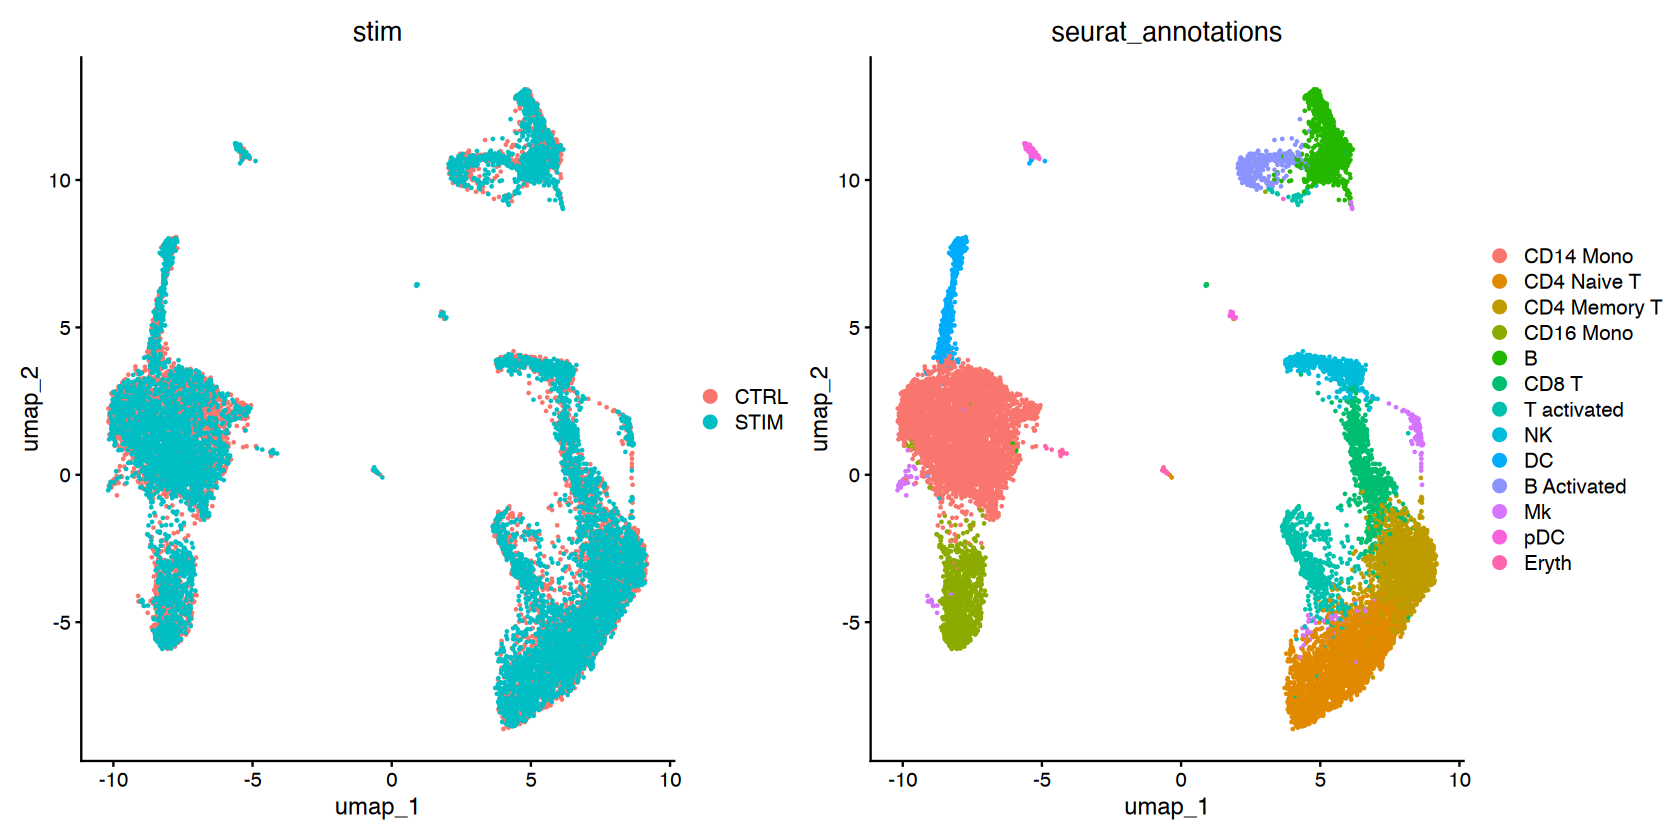

In [32]:
# Visualization
DimPlot(ifnb, reduction = "umap", group.by = c("stim", "seurat_annotations"))

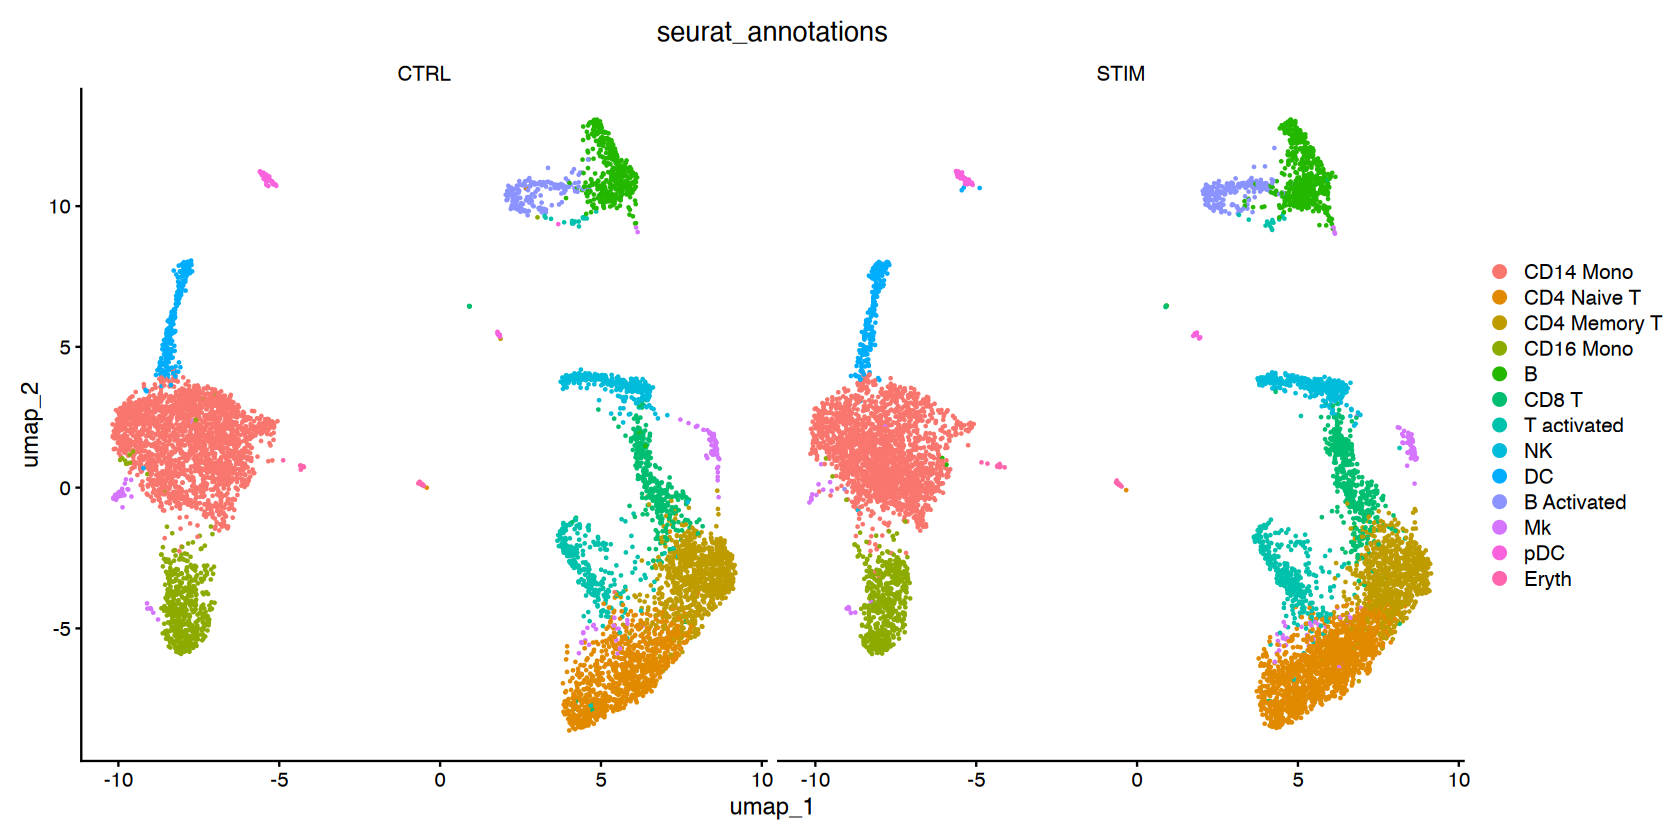

In [33]:
DimPlot(ifnb, reduction = "umap", group.by = "seurat_annotations", split.by = "stim", ncol=2)

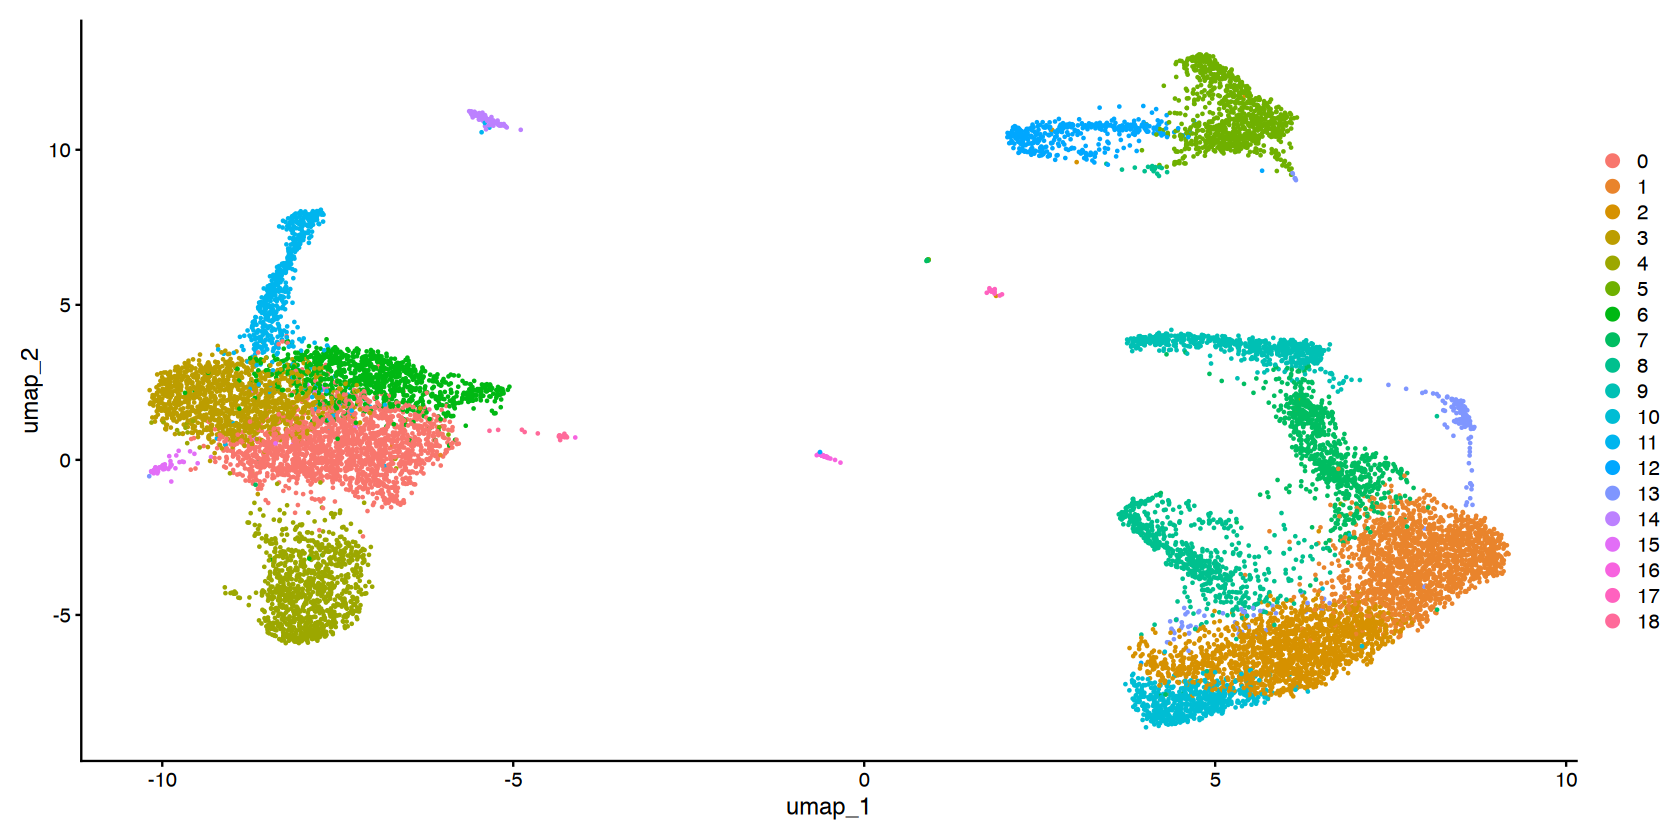

In [34]:
DimPlot(ifnb, reduction = "umap")

In [36]:
Idents(ifnb) <- "seurat_annotations"
nk.markers <- FindConservedMarkers(ifnb, ident.1 = "NK", grouping.var = "stim", verbose = FALSE)
head(nk.markers)

,CTRL_p_val,CTRL_avg_log2FC,CTRL_pct.1,CTRL_pct.2,CTRL_p_val_adj,STIM_p_val,STIM_avg_log2FC,STIM_pct.1,STIM_pct.2,STIM_p_val_adj,max_pval,minimump_p_val
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
GNLY,0,6.854586,0.943,0.046,0,0,6.435910,0.956,0.059,0,0,0
NKG7,0,5.358881,0.953,0.085,0,0,4.971397,0.950,0.081,0,0,0
GZMB,0,5.078135,0.839,0.044,0,0,5.151924,0.897,0.060,0,0,0
CLIC3,0,5.765314,0.601,0.024,0,0,5.505208,0.623,0.031,0,0,0
CTSW,0,5.307246,0.537,0.030,0,0,5.240729,0.592,0.035,0,0,0
KLRD1,0,5.261553,0.507,0.019,0,0,4.852457,0.555,0.027,0,0,0


In [37]:
ifnb[[]]

,orig.ident,nCount_RNA,nFeature_RNA,stim,seurat_annotations,RNA_snn_res.2,seurat_clusters,RNA_snn_res.1
,<chr>,<dbl>,<int>,<chr>,<fct>,<fct>,<fct>,<fct>
AAACATACATTTCC.1,IMMUNE_CTRL,3017,877,CTRL,CD14 Mono,6,3,3
AAACATACCAGAAA.1,IMMUNE_CTRL,2481,713,CTRL,CD14 Mono,6,0,0
AAACATACCTCGCT.1,IMMUNE_CTRL,3420,850,CTRL,CD14 Mono,6,0,0
AAACATACCTGGTA.1,IMMUNE_CTRL,3156,1109,CTRL,pDC,22,14,14
AAACATACGATGAA.1,IMMUNE_CTRL,1868,634,CTRL,CD4 Memory T,5,1,1
AAACATACGGCATT.1,IMMUNE_CTRL,1581,557,CTRL,CD14 Mono,0,6,6
AAACATACTGCGTA.1,IMMUNE_CTRL,2747,980,CTRL,T activated,9,8,8
AAACATACTGCTGA.1,IMMUNE_CTRL,1341,581,CTRL,CD4 Naive T,2,2,2
AAACATTGAGTGTC.1,IMMUNE_CTRL,2155,880,CTRL,CD8 T,17,7,7


In [38]:
Idents(ifnb)

AAACATACATTTCC.1  AAACATACCAGAAA.1  AAACATACCTCGCT.1  AAACATACCTGGTA.1 
        CD14 Mono         CD14 Mono         CD14 Mono               pDC 
 AAACATACGATGAA.1  AAACATACGGCATT.1  AAACATACTGCGTA.1  AAACATACTGCTGA.1 
     CD4 Memory T         CD14 Mono       T activated       CD4 Naive T 
 AAACATTGAGTGTC.1  AAACATTGCTTCGC.1  AAACCGTGAGCCAT.1  AAACCGTGGAGGCA.1 
            CD8 T         CD14 Mono       CD4 Naive T       T activated 
 AAACCGTGTGCTAG.1  AAACGCACACTTTC.1  AAACGCACAGTACC.1  AAACGCACCAACCA.1 
            CD8 T             CD8 T                Mk       CD4 Naive T 
 AAACGCACGCTGTA.1  AAACGCACGGGAGT.1  AAACGCACTCGCCT.1  AAACGCTGACCTTT.1 
      T activated       CD4 Naive T         CD14 Mono       T activated 
 AAACGCTGCAGTTG.1  AAACGCTGCCTAAG.1  AAACGCTGCGTTGA.1  AAACGCTGCTGACA.1 
            CD8 T      CD4 Memory T       CD4 Naive T       B Activated 
 AAACGCTGGATAAG.1  AAACGCTGGGACAG.1  AAACGCTGGGGATG.1  AAACGCTGGGTTTG.1 
      CD4 Naive T         CD14 Mono         CD14 Mono             CD8 T 
 AAACGCTGTAGCGT.1  AAACGCTGTGCTAG.1  AAACGCTGTTCCAT.1  AAACGGCTAGAGTA.1 
                B       B Activated      CD4 Memory T         CD14 Mono 
 AAACGGCTAGTACC.1  AAACGGCTCTTCGC.1  AAACGGCTGGTCAT.1  AAACGGCTTACTCT.1 
      CD4 Naive T                DC       T activated         CD16 Mono 
 AAACGGCTTCTCTA.1  AAACTTGACCTGAA.1  AAACTTGACTCTTA.1  AAACTTGACTGAGT.1 
        CD14 Mono         CD14 Mono                NK                 B 
 AAACTTGACTGGAT.1  AAACTTGAGACGAG.1  AAACTTGAGCCCTT.1  AAACTTGAGGAAAT.1 
        CD16 Mono                NK      CD4 Memory T      CD4 Memory T 
 AAAGACGAAACAGA.1  AAAGACGAACACGT.1  AAAGACGAAGTCTG.1  AAAGACGACCCGTT.1 
        CD14 Mono      CD4 Memory T       CD4 Naive T                NK 
 AAAGACGACGCCTT.1  AAAGACGACGGAGA.1  AAAGACGAGTAAGA.1  AAAGAGACGAGGTG.1 
            CD8 T       CD4 Naive T         CD14 Mono         CD14 Mono 
 AAAGAGACTCAGAC.1  AAAGAGACTCTGGA.1  AAAGATCTACCCTC.1  AAAGATCTGACACT.1 
      CD4 Naive T      CD4 Memory T         CD14 Mono       CD4 Naive T 
 AAAGATCTTGCAGT.1  AAAGCAGAAGTTCG.1  AAAGCAGAGTTTCT.1  AAAGCAGATGCAAC.1 
        CD14 Mono                Mk         CD14 Mono         CD16 Mono 
 AAAGCCTGAAGTAG.1  AAAGCCTGACGTGT.1  AAAGCCTGCTAGCA.1  AAAGCCTGGCTAAC.1 
        CD14 Mono       CD4 Naive T                 B             CD8 T 
 AAAGCCTGGGATTC.1  AAAGCCTGTACAGC.1  AAAGCCTGTGGTAC.1  AAAGGCCTAAACGA.1 
        CD16 Mono             CD8 T      CD4 Memory T         CD16 Mono 
 AAAGGCCTAGTCTG.1  AAAGGCCTCGAGAG.1  AAAGGCCTGAGGAC.1  AAAGTTTGAACCAC.1 
        CD14 Mono                Mk         CD16 Mono                 B 
 AAAGTTTGACTCTT.1  AAAGTTTGCGAGAG.1  AAAGTTTGCTGAGT.1  AAAGTTTGCTTCTA.1 
      T activated         CD16 Mono      CD4 Memory T       B Activated 
 AAAGTTTGTAGCGT.1  AAAGTTTGTGTGGT.1  AAAGTTTGTTCGTT.1  AAATACTGGGTTCA.1 
     CD4 Memory T         CD14 Mono         CD14 Mono         CD16 Mono 
 AAATACTGGTTCTT.1  AAATACTGGTTGAC.1  AAATCAACCTGTAG.1  AAATCAACGGTCAT.1 
        CD14 Mono       T activated         CD16 Mono         CD14 Mono 
 AAATCAACGTCGTA.1  AAATCATGACACCA.1  AAATCATGACACGT.1  AAATCATGCTCTAT.1 
               DC       CD4 Naive T      CD4 Memory T         CD14 Mono 
 AAATCATGGAGAGC.1  AAATCATGGGTTCA.1  AAATCCCTAAGAAC.1  AAATCCCTACACAC.1 
        CD14 Mono         CD14 Mono         CD14 Mono      CD4 Memory T 
 AAATCCCTCTTGAG.1  AAATCCCTGCTATG.1  AAATCCCTGTTGAC.1  AAATCCCTTAGCGT.1 
        CD14 Mono      CD4 Memory T         CD14 Mono                NK 
 AAATCCCTTTCCAT.1  AAATCTGACTTTAC.1  AAATCTGAGCTTCC.1  AAATGGGAAACCTG.1 
                B                 B         CD14 Mono                Mk 
 AAATGGGACCTTTA.1  AAATGGGACTCATT.1  AAATGGGAGACAGG.1  AAATGGGAGGGAGT.1 
        CD16 Mono             CD8 T                 B         CD14 Mono 
 AAATGGGAGTCCTC.1  AAATGGGAGTCTGA.1  AAATGTTGAGAGTA.1  AAATGTTGAGCTCA.1 
      CD4 Naive T         CD14 Mono                NK         CD14 Mono 
 AAATGTTGCCAAGT.1  AAATGTTGCCTCCA.1  AAATGTTGTCTTTG.1  AAAT

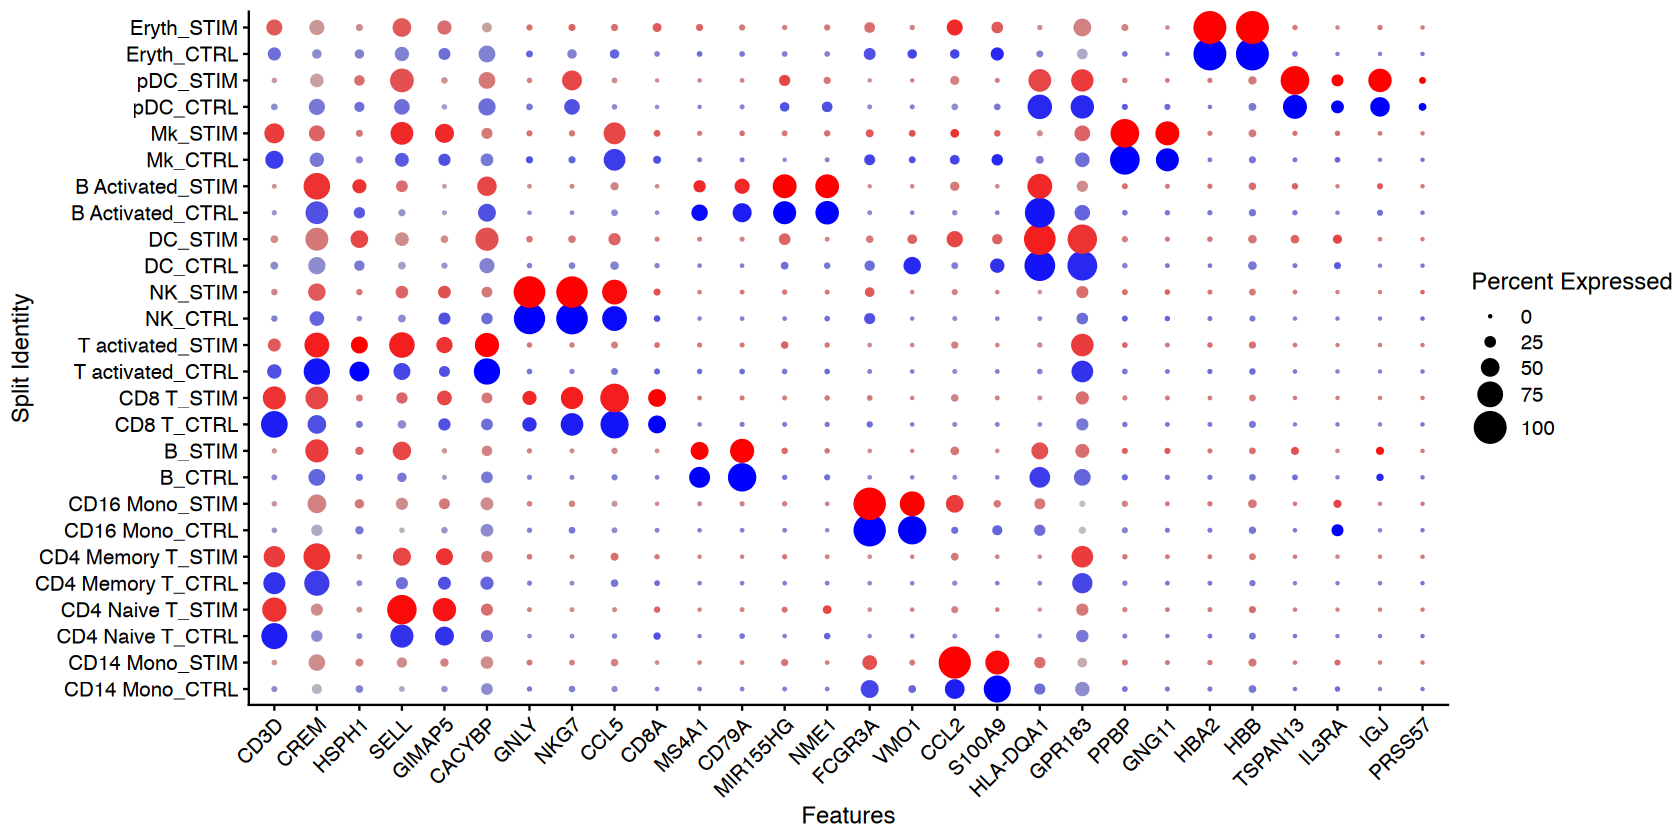

In [39]:
markers.to.plot <- c("CD3D", "CREM", "HSPH1", "SELL", "GIMAP5", "CACYBP", "GNLY", "NKG7", "CCL5",
    "CD8A", "MS4A1", "CD79A", "MIR155HG", "NME1", "FCGR3A", "VMO1", "CCL2", "S100A9", "HLA-DQA1",
    "GPR183", "PPBP", "GNG11", "HBA2", "HBB", "TSPAN13", "IL3RA", "IGJ", "PRSS57")
DotPlot(ifnb, features = markers.to.plot, cols = c("blue", "red"), dot.scale = 8, split.by = "stim") +
    RotatedAxis()

In [40]:
library(ggplot2)
library(cowplot)
theme_set(theme_cowplot())

aggregate_ifnb <- AggregateExpression(ifnb, group.by = c("seurat_annotations", "stim"), return.seurat = TRUE)


Attaching package: ‘cowplot’


The following object is masked from ‘package:patchwork’:

    align_plots


Centering and scaling data matrix



In [41]:
aggregate_ifnb

An object of class Seurat 
14053 features across 26 samples within 1 assay 
Active assay: RNA (14053 features, 0 variable features)
 3 layers present: counts, data, scale.data

In [42]:
aggregate_ifnb[[]]

,orig.ident,seurat_annotations,stim
,<chr>,<chr>,<chr>
CD14 Mono_CTRL,CD14 Mono_CTRL,CD14 Mono,CTRL
CD14 Mono_STIM,CD14 Mono_STIM,CD14 Mono,STIM
CD4 Naive T_CTRL,CD4 Naive T_CTRL,CD4 Naive T,CTRL
CD4 Naive T_STIM,CD4 Naive T_STIM,CD4 Naive T,STIM
CD4 Memory T_CTRL,CD4 Memory T_CTRL,CD4 Memory T,CTRL
CD4 Memory T_STIM,CD4 Memory T_STIM,CD4 Memory T,STIM
CD16 Mono_CTRL,CD16 Mono_CTRL,CD16 Mono,CTRL
CD16 Mono_STIM,CD16 Mono_STIM,CD16 Mono,STIM
B_CTRL,B_CTRL,B,CTRL


In [43]:
aggregate_ifnb[["RNA"]]$counts

  [[ suppressing 26 column names ‘CD14 Mono_CTRL’, ‘CD14 Mono_STIM’, ‘CD4 Naive T_CTRL’ ... ]]

  [[ suppressing 26 column names ‘CD14 Mono_CTRL’, ‘CD14 Mono_STIM’, ‘CD4 Naive T_CTRL’ ... ]]

  [[ suppressing 26 column names ‘CD14 Mono_CTRL’, ‘CD14 Mono_STIM’, ‘CD4 Naive T_CTRL’ ... ]]



14053 x 26 sparse Matrix of class "dgCMatrix"
                                                                                
AL627309.1         .      .     1     .    1    .    .     .    .    .    1    .
RP11-206L10.2      1      .     1     .    .    .    .     .    1    .    .    .
LINC00115          9      8     2     .    4    2    4     4    1    1    1    1
NOC2L             83     38   109   182   73   56   48    20   39   55   30   30
KLHL17             5      1     2     .    .    1    2     1    1    1    1    .
PLEKHN1           14     35     1     1    .    7    1     4    .    2    1    2
HES4              19   2594     3    27   10   49   28   791    3   27    7   19
ISG15           2587 275838   248 11865  338 9278 1061 52019  162 7887  176 4975
AGRN               9     20     .     3    .    1    .     .    .    1    .    1
C1orf159           5      1     4     7    2    4    1     2    1    1    .    3
TNFRSF18          28     22     8    10  123  102    8     2   

In [44]:
genes.to.label = c("ISG15", "LY6E", "IFI6", "ISG20", "MX1", "IFIT2", "IFIT1", "CXCL10", "CCL8")

When using repel, set xnudge and ynudge to 0 for optimal results

When using repel, set xnudge and ynudge to 0 for optimal results



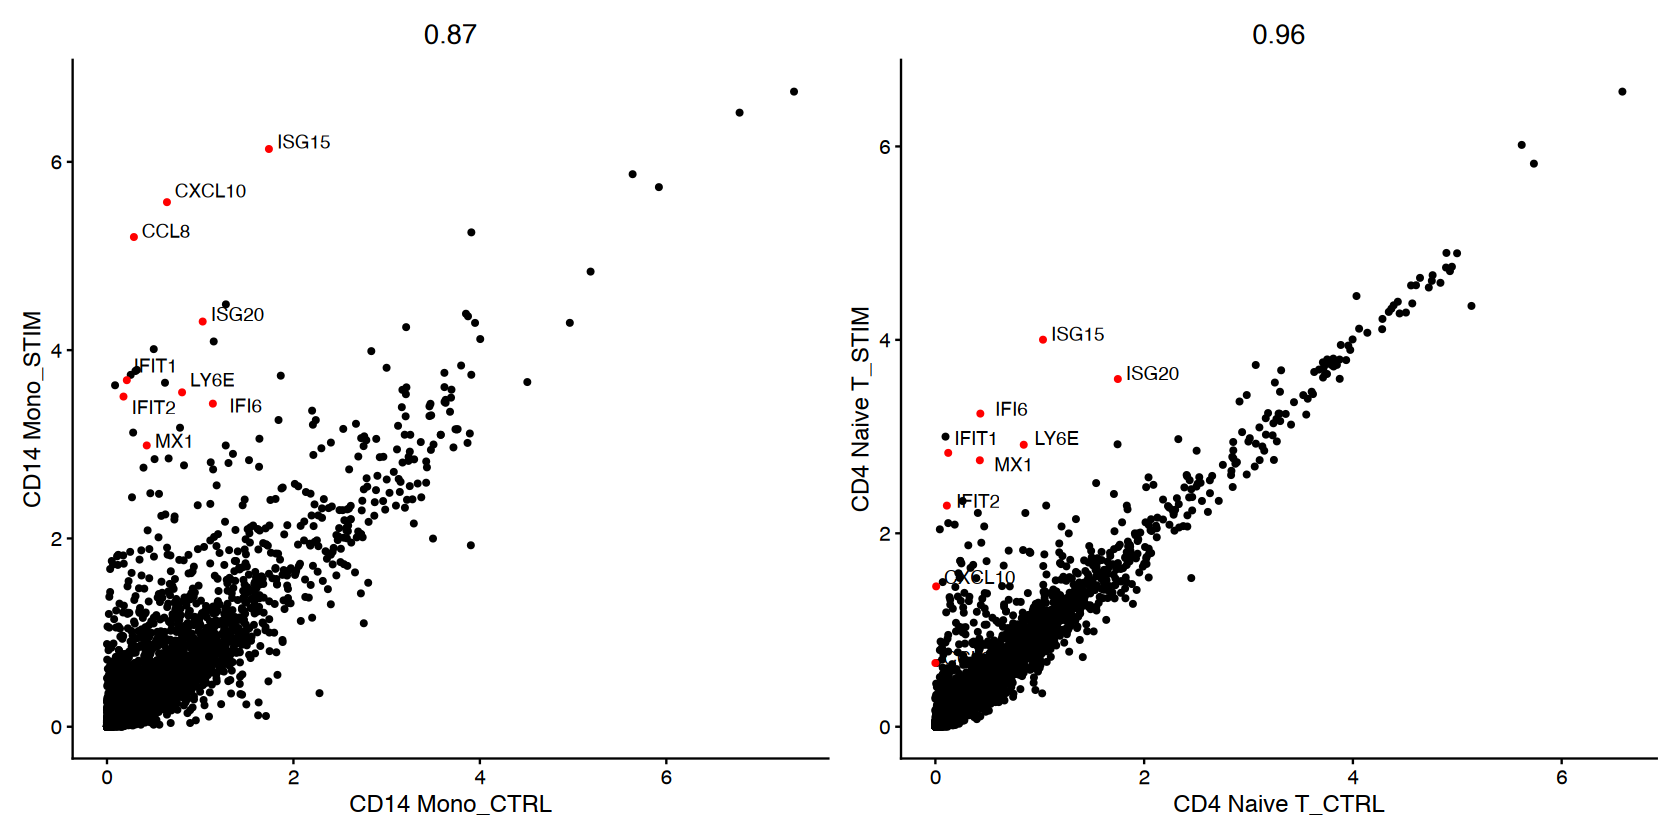

In [45]:
p1 <- CellScatter(aggregate_ifnb, "CD14 Mono_CTRL", "CD14 Mono_STIM", highlight = genes.to.label)
p2 <- LabelPoints(plot = p1, points = genes.to.label, repel = TRUE)

p3 <- CellScatter(aggregate_ifnb, "CD4 Naive T_CTRL", "CD4 Naive T_STIM", highlight = genes.to.label)
p4 <- LabelPoints(plot = p3, points = genes.to.label, repel = TRUE)

p2 + p4

In [46]:
ifnb$celltype.stim <- paste(ifnb$seurat_annotations, ifnb$stim, sep = "_")

In [47]:
ifnb[[]]

,orig.ident,nCount_RNA,nFeature_RNA,stim,seurat_annotations,RNA_snn_res.2,seurat_clusters,RNA_snn_res.1,celltype.stim
,<chr>,<dbl>,<int>,<chr>,<fct>,<fct>,<fct>,<fct>,<chr>
AAACATACATTTCC.1,IMMUNE_CTRL,3017,877,CTRL,CD14 Mono,6,3,3,CD14 Mono_CTRL
AAACATACCAGAAA.1,IMMUNE_CTRL,2481,713,CTRL,CD14 Mono,6,0,0,CD14 Mono_CTRL
AAACATACCTCGCT.1,IMMUNE_CTRL,3420,850,CTRL,CD14 Mono,6,0,0,CD14 Mono_CTRL
AAACATACCTGGTA.1,IMMUNE_CTRL,3156,1109,CTRL,pDC,22,14,14,pDC_CTRL
AAACATACGATGAA.1,IMMUNE_CTRL,1868,634,CTRL,CD4 Memory T,5,1,1,CD4 Memory T_CTRL
AAACATACGGCATT.1,IMMUNE_CTRL,1581,557,CTRL,CD14 Mono,0,6,6,CD14 Mono_CTRL
AAACATACTGCGTA.1,IMMUNE_CTRL,2747,980,CTRL,T activated,9,8,8,T activated_CTRL
AAACATACTGCTGA.1,IMMUNE_CTRL,1341,581,CTRL,CD4 Naive T,2,2,2,CD4 Naive T_CTRL
AAACATTGAGTGTC.1,IMMUNE_CTRL,2155,880,CTRL,CD8 T,17,7,7,CD8 T_CTRL


In [48]:
Idents(ifnb) <- "celltype.stim"

In [49]:
b.interferon.response <- FindMarkers(ifnb, ident.1 = "B_STIM", ident.2 = "B_CTRL", verbose = TRUE)

In [50]:
head(b.interferon.response, n = 15)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ISG15,5.387767e-159,5.0588481,0.998,0.233,7.571429e-155
IFIT3,1.945114e-154,6.1124940,0.965,0.052,2.733468e-150
IFI6,2.503565e-152,5.4933132,0.965,0.076,3.518260e-148
ISG20,6.492570e-150,3.0549593,1.000,0.668,9.124009e-146
IFIT1,1.951022e-139,6.2320388,0.907,0.029,2.741772e-135
MX1,6.897626e-123,3.9798482,0.905,0.115,9.693234e-119
LY6E,2.825649e-120,3.7907800,0.898,0.150,3.970885e-116
TNFSF10,4.007285e-112,6.5802175,0.786,0.020,5.631437e-108
IFIT2,2.672552e-108,5.5525558,0.786,0.037,3.755738e-104


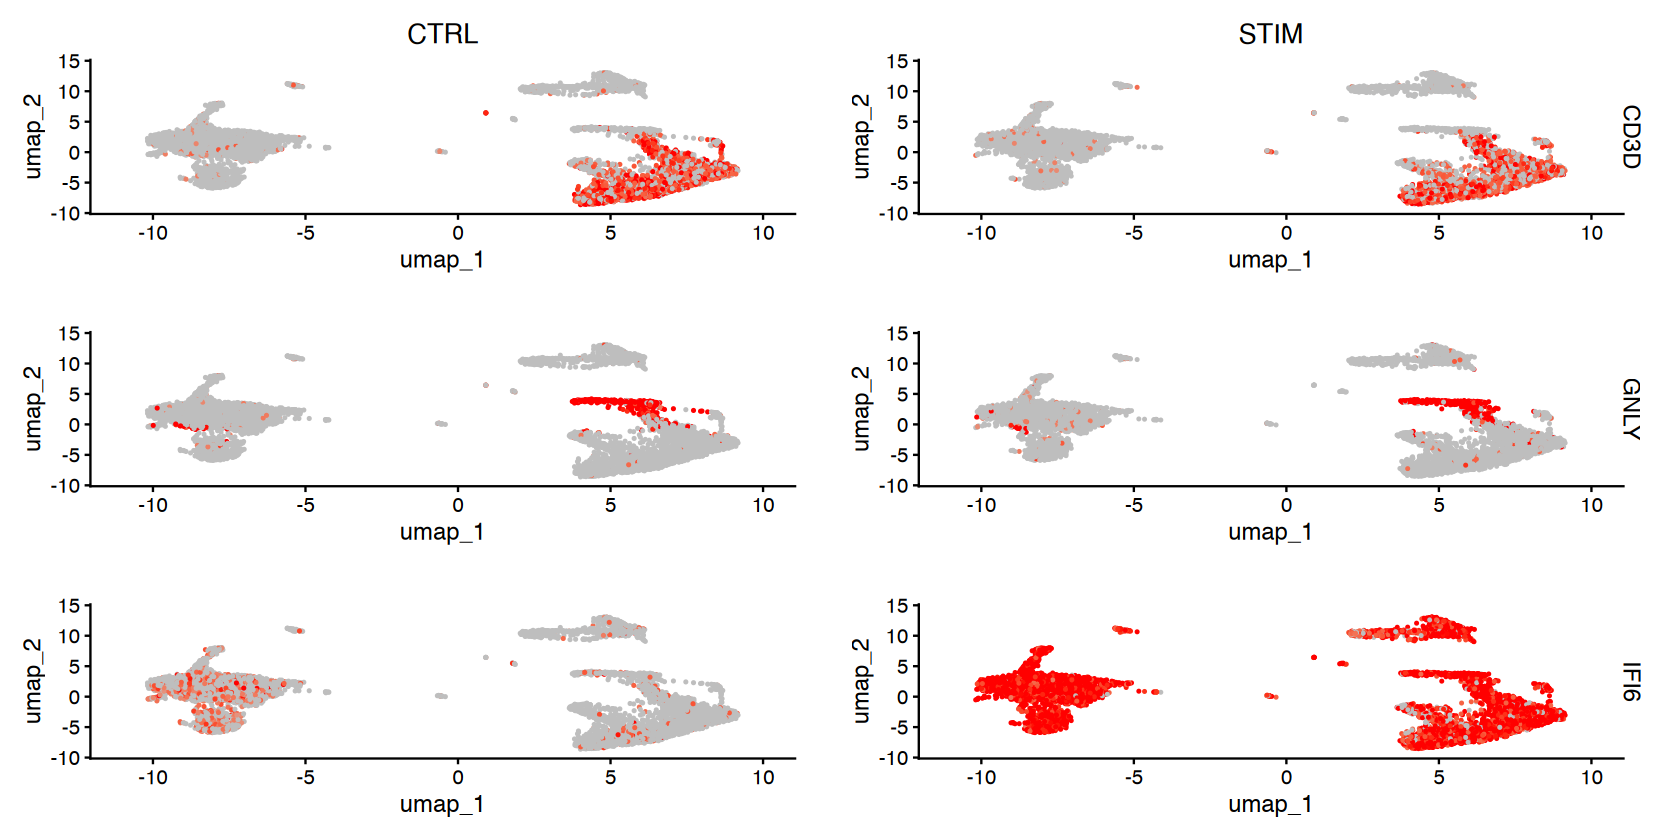

In [51]:
FeaturePlot(ifnb, features = c("CD3D", "GNLY", "IFI6"), split.by = "stim", max.cutoff = 3, cols = c("grey",
    "red"), reduction = "umap")

The default behaviour of split.by has changed.
Separate violin plots are now plotted side-by-side.
To restore the old behaviour of a single split violin,
set split.plot = TRUE.
      
This message will be shown once per session.



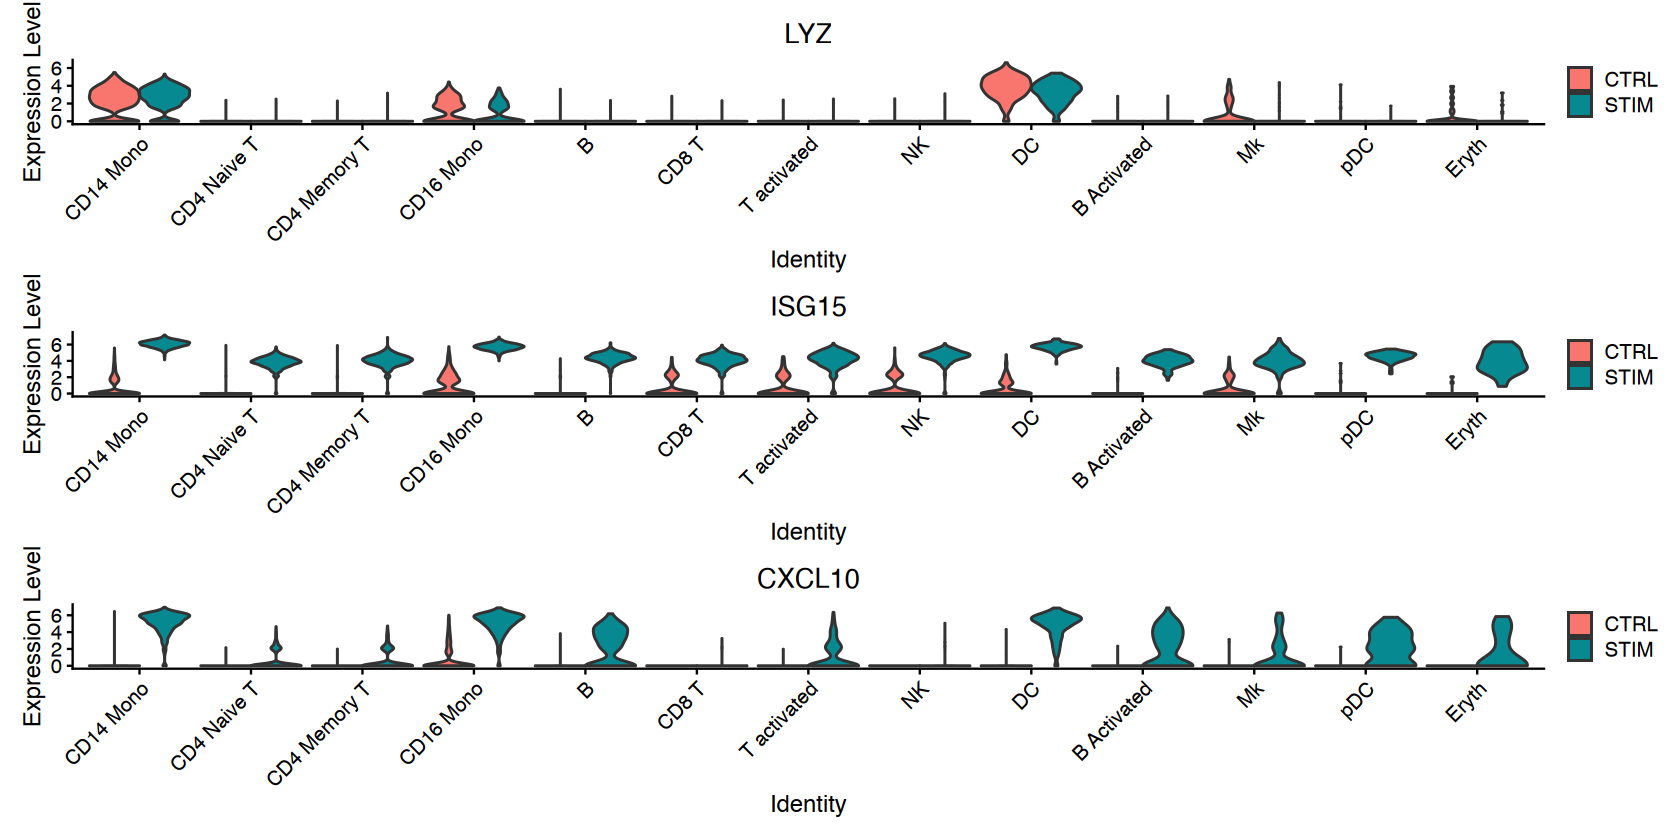

In [52]:
plots <- VlnPlot(ifnb, features = c("LYZ", "ISG15", "CXCL10"), split.by = "stim", group.by = "seurat_annotations",
    pt.size = 0, combine = FALSE)
wrap_plots(plots = plots, ncol = 1)

In [53]:
ifnb

An object of class Seurat 
14053 features across 13999 samples within 1 assay 
Active assay: RNA (14053 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 dimensional reductions calculated: pca, umap.unintegrated, integrated.cca, umap